# Notebook 03 — Feature Engineering

**Enterprise Credit Risk Modeling & Validation Framework**

**Input:** `data/interim/clean_data.parquet`

**Outputs:** `data/processed/train.parquet` · `val.parquet` · `oot.parquet`

## Design Principle

One **master cleaned dataset** is produced here. Every model starts from the
**same** train / val / oot parquets. Model-specific feature selection happens inside each
model notebook:

- **Logistic Regression Scorecard** → WoE encoding + IV + VIF + p-values
- **Random Forest / XGBoost** → all master features; feature importance after training
- **Cox PHM** → survival-specific variable selection

WoE / IV analysis in Section 5 is an **analytical reference only** — it informs LR feature selection but does NOT permanently remove variables from the master dataset.

## Sections
1. Feature Removal — Justify every removed column with quantitative evidence
2. Master Dataset — Document every retained feature with business justification
3. Outlier Capping
4. Out-of-Time Split — Train (2007–2015) · Val (2016) · OOT (2017–2018)
5. WoE / IV Analysis — Analytical reference for LR feature selection
6. Save Master Splits


In [ ]:
import warnings
warnings.filterwarnings('ignore')

import os, sys, json
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
if '' not in sys.path:
    sys.path.insert(0, '')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 80)
pd.set_option('display.float_format', '{:.4f}'.format)

from src.utils import setup_logging, set_plot_style, save_figure, PLOT_COLOR, ACCENT_COLOR
from src.preprocessing import create_oot_split, compute_woe_iv

setup_logging()
set_plot_style()

INTERIM_PATH  = 'data/interim/clean_data.parquet'
PROCESSED_DIR = 'data/processed'
WOE_DIR       = 'artifacts/woe_tables'
os.makedirs(WOE_DIR, exist_ok=True)

print('Setup complete. Working directory:', os.getcwd())

Setup complete. Working directory: [project root]


In [ ]:
df = pd.read_parquet(INTERIM_PATH)
print(f'Loaded: {df.shape[0]:,} rows x {df.shape[1]} columns')

Loaded: 2,260,638 rows x 96 columns


## 1. Feature Removal — Justified by Evidence

Every removed column has an explicit reason from this vocabulary:

| Code | Meaning |
|------|---------|
| `HIGH_MISSING` | 38%+ missing — pre-2015 Lending Club data gap (credit bureau fields added later) |
| `REDUNDANT` | Pearson r >= 0.75 with a retained feature |
| `MOD_REDUNDANT` | 0.40 <= r < 0.75 with a more general retained feature |
| `NEAR_CONSTANT` | IV < 0.001 — near-zero discriminatory power |

**None of the Group B features are removed for low IV alone.** IV is shown only as additional context.

In [ ]:
# column -> (reason_code, quantitative_evidence, retained_alternative)
REMOVED_COLS = {
    # ── HIGH MISSING: 38-67% — pre-2015 credit bureau field gap ──────────────
    'mths_since_recent_revol_delinq': ('HIGH_MISSING',  '67.2% missing',          'mths_since_last_delinq'),
    'il_util':          ('HIGH_MISSING',  '47.3% missing',              'revol_util'),
    'mths_since_rcnt_il':('HIGH_MISSING', '40.2% missing',              'mo_sin_rcnt_tl'),
    'max_bal_bc':       ('HIGH_MISSING',  '38.3% missing',              'revol_bal + bc_util'),
    'all_util':         ('HIGH_MISSING',  '38.3% missing',              'revol_util'),
    'open_il_12m':      ('HIGH_MISSING',  '38.3% missing',              'num_il_tl'),
    'open_il_24m':      ('HIGH_MISSING',  '38.3% missing',              'num_il_tl'),
    'total_bal_il':     ('HIGH_MISSING',  '38.3% missing',              'total_bal_ex_mort'),
    'open_rv_12m':      ('HIGH_MISSING',  '38.3% missing',              'open_acc'),
    'open_rv_24m':      ('HIGH_MISSING',  '38.3% missing',              'open_acc'),
    'inq_last_12m':     ('HIGH_MISSING',  '38.3% missing',              'inq_last_6mths'),
    'total_cu_tl':      ('HIGH_MISSING',  '38.3% missing',              'num_il_tl'),
    'inq_fi':           ('HIGH_MISSING',  '38.3% missing',              'inq_last_6mths'),
    'open_acc_6m':      ('HIGH_MISSING',  '38.3% missing',              'open_acc'),
    'open_act_il':      ('HIGH_MISSING',  '38.3% missing + IV=0.0004 + r=0.65 with num_il_tl', 'num_il_tl'),

    # ── REDUNDANT: r >= 0.75 with retained feature ────────────────────────────
    'num_rev_tl_bal_gt_0': ('REDUNDANT',   'r=0.98 with num_actv_rev_tl',           'num_actv_rev_tl'),
    'mo_sin_old_rev_tl_op':('REDUNDANT',   'r=0.92 with mths_since_earliest_cr_line','mths_since_earliest_cr_line'),
    'percent_bc_gt_75':    ('REDUNDANT',   'r=0.85 with bc_util',                   'bc_util'),
    'avg_cur_bal':         ('REDUNDANT',   'r=0.83 with tot_cur_bal',               'tot_cur_bal'),
    'num_op_rev_tl':       ('REDUNDANT',   'r=0.84 with open_acc',                  'open_acc'),
    'num_actv_bc_tl':      ('REDUNDANT',   'r=0.82 with num_actv_rev_tl',           'num_actv_rev_tl'),
    'total_bc_limit':      ('REDUNDANT',   'r=0.76 with total_rev_hi_lim',          'total_rev_hi_lim'),
    'num_rev_accts':       ('REDUNDANT',   'r=0.76 with total_acc',                 'total_acc'),

    # ── MOD_REDUNDANT: 0.40 <= r < 0.75, subset concept ──────────────────────
    'mo_sin_rcnt_rev_tl_op':('MOD_REDUNDANT','r=0.61 with mo_sin_rcnt_tl (revolving subset)','mo_sin_rcnt_tl'),
    'num_bc_sats':          ('MOD_REDUNDANT','r=0.64 with num_sats (bank card subset)',       'num_sats'),
    'num_bc_tl':            ('MOD_REDUNDANT','r=0.54 with num_sats (bank card subset)',       'num_sats'),
    'total_il_high_credit_limit':('MOD_REDUNDANT','r=0.43 with tot_hi_cred_lim (installment subset)','tot_hi_cred_lim'),
    'bc_open_to_buy':       ('MOD_REDUNDANT','r=-0.54 with bc_util (complement; same credit capacity info)','bc_util'),
    'mo_sin_old_il_acct':   ('MOD_REDUNDANT','installment-specific version of mths_since_earliest_cr_line','mths_since_earliest_cr_line'),

    # ── NEAR_CONSTANT: essentially no discriminatory power ────────────────────
    'delinq_amnt':       ('NEAR_CONSTANT', '>99% zero values; no signal',           'delinq_2yrs'),
    'chargeoff_within_12_mths':('NEAR_CONSTANT','IV=0.0001; near-zero variance',    'num_accts_ever_120_pd'),
    'num_tl_120dpd_2m':  ('NEAR_CONSTANT', 'IV=0.0002; 6.8% missing; near-zero',   'num_tl_90g_dpd_24m'),
    'num_tl_30dpd':      ('NEAR_CONSTANT', '30-day threshold too mild; superseded by delinq_2yrs + num_accts_ever_120_pd', 'delinq_2yrs'),
}

print(f'Columns to remove from Group B: {len(REMOVED_COLS)}')
print()
print(f'{"Column":<40} {"Code":<16} Evidence')
print('-' * 100)
for col, (code, evidence, alt) in REMOVED_COLS.items():
    present = '(in data)' if col in df.columns else '(not in data — already dropped)'
    print(f'{col:<40} {code:<16} {evidence}')

Columns to remove from Group B: 33

Column                                   Code             Evidence
----------------------------------------------------------------------------------------------------
mths_since_recent_revol_delinq           HIGH_MISSING     67.2% missing
il_util                                  HIGH_MISSING     47.3% missing
mths_since_rcnt_il                       HIGH_MISSING     40.2% missing
max_bal_bc                               HIGH_MISSING     38.3% missing
all_util                                 HIGH_MISSING     38.3% missing
open_il_12m                              HIGH_MISSING     38.3% missing
open_il_24m                              HIGH_MISSING     38.3% missing
total_bal_il                             HIGH_MISSING     38.3% missing
open_rv_12m                              HIGH_MISSING     38.3% missing
open_rv_24m                              HIGH_MISSING     38.3% missing
inq_last_12m                             HIGH_MISSING     38.3% missing
tota

## 2. Master Dataset — 48 Features

The master dataset is defined by an **explicit KEEP list** — safer than a DROP list.
Features are grouped by credit risk category for clarity.

In [ ]:
MASTER_COLS = [
    # ─── Loan Characteristics ───────────────────────────────────────────────
    'loan_amnt', 'term', 'int_rate', 'installment',
    # ─── Credit Grade (assigned by LC at application) ────────────────────────
    'grade', 'sub_grade',
    # ─── Borrower Employment & Income ───────────────────────────────────────
    'emp_length', 'annual_inc', 'verification_status',
    # ─── Housing ────────────────────────────────────────────────────────────
    'home_ownership',
    # ─── Loan Purpose & Geography ───────────────────────────────────────────
    'purpose', 'addr_state',
    # ─── Bureau: Debt Burden ────────────────────────────────────────────────
    'dti',
    # ─── Bureau: Delinquency History ────────────────────────────────────────
    'delinq_2yrs', 'inq_last_6mths', 'mths_since_last_delinq',
    'pub_rec', 'pub_rec_bankruptcies', 'tax_liens',
    'acc_now_delinq', 'collections_12_mths_ex_med',
    # ─── Bureau: Credit Lines ───────────────────────────────────────────────
    'open_acc', 'total_acc',
    # ─── Bureau: Revolving Credit ───────────────────────────────────────────
    'revol_bal', 'revol_util',
    # ─── Bureau: Credit History Length ──────────────────────────────────────
    'mths_since_earliest_cr_line',
    # ─── FICO Scores at Origination ─────────────────────────────────────────
    'fico_range_low', 'fico_range_high',
    # ─── LC Operational ─────────────────────────────────────────────────────
    'initial_list_status',
    # ─── Group B: Indebtedness ───────────────────────────────────────────────
    'tot_cur_bal', 'total_rev_hi_lim', 'tot_hi_cred_lim',
    'total_bal_ex_mort', 'tot_coll_amt',
    # ─── Group B: Bank Card & Revolving ─────────────────────────────────────
    'bc_util', 'num_actv_rev_tl',
    # ─── Group B: Account Depth ──────────────────────────────────────────────
    'num_il_tl', 'num_sats', 'mort_acc',
    # ─── Group B: Severe Delinquency ────────────────────────────────────────
    'num_accts_ever_120_pd', 'num_tl_90g_dpd_24m',
    # ─── Group B: Credit Activity & Recency ─────────────────────────────────
    'num_tl_op_past_12m', 'acc_open_past_24mths',
    'mo_sin_rcnt_tl', 'mths_since_recent_inq', 'mths_since_recent_bc',
    # ─── Group B: Payment Track Record ──────────────────────────────────────
    'pct_tl_nvr_dlq',
    # ─── Special: Targets & Split Key ───────────────────────────────────────
    'issue_d', 'default', 'recovery_rate', 'credit_conversion_factor',
]

missing_from_data = [c for c in MASTER_COLS if c not in df.columns]
if missing_from_data:
    print(f'WARNING — columns not in data: {missing_from_data}')
else:
    print(f'All {len(MASTER_COLS)} master columns confirmed in dataset.')

df_master = df[[c for c in MASTER_COLS if c in df.columns]].copy()
n_features = len(MASTER_COLS) - 4
print(f'Master dataset: {df_master.shape[0]:,} rows x {df_master.shape[1]} columns')
print(f'  Model features: {n_features} | Special (targets + date): 4')
print(f'  Removed vs clean_data.parquet: {df.shape[1] - df_master.shape[1]} columns')

All 51 master columns confirmed in dataset.
Master dataset: 2,260,638 rows x 51 columns
  Model features: 47 | Special (targets + date): 4
  Removed vs clean_data.parquet: 45 columns


In [ ]:
# Feature retention documentation — for dissertation, reports, and interview discussions
RETENTION_DOCS = [
    # Feature, Category, Why Retained
    ('loan_amnt',    'Loan',         'Requested amount; primary driver of exposure at default'),
    ('term',         'Loan',         '36 vs 60 months; 60m loans: 17.6% vs 11.0% default rate; IV=0.127 (Medium)'),
    ('int_rate',     'Loan',         'Strongest PD predictor (IV=0.403 Strong); set by LC based on borrower credit risk'),
    ('installment',  'Loan',         'Monthly payment; R²=0.976 from loan_amnt+rate+term but kept for tree models'),
    ('grade',        'Credit Grade', 'LC A–G grade; monotonic default increase; IV=0.412 (Strong)'),
    ('sub_grade',    'Credit Grade', '35-level granular grade; highest IV=0.443 (Strong) in entire dataset'),
    ('emp_length',   'Employment',   'Employment stability 0–10 years; proxy for income reliability'),
    ('annual_inc',   'Employment',   'Primary income measure; inversely related to default; IV=0.035 (Weak)'),
    ('verification_status','Employment','LC income verification; verified borrowers show lower default; IV=0.046'),
    ('home_ownership','Housing',     'MORTGAGE < OWN < RENT default rate; IV=0.023'),
    ('purpose',      'Loan Purpose', 'Debt consolidation vs other uses differ in risk profile; IV=0.021'),
    ('addr_state',   'Geography',    'Regional risk variation across 50 US states'),
    ('dti',          'Debt Burden',  'Debt-to-income ratio; core affordability metric; IV=0.060 (Weak but essential)'),
    ('delinq_2yrs',  'Delinquency',  '30+ DPD events in past 2 years; recent payment behaviour'),
    ('inq_last_6mths','Delinquency', 'Recent credit inquiries; >2 associated with higher risk; IV=0.022'),
    ('mths_since_last_delinq','Delinquency','Recency of last delinquency; NaN = never delinquent (best category)'),
    ('pub_rec',      'Delinquency',  'Public derogatory records (court judgements, etc.)'),
    ('pub_rec_bankruptcies','Delinquency','Bankruptcy count; severe negative creditworthiness signal'),
    ('tax_liens',    'Delinquency',  'Outstanding tax liens; government-priority debt'),
    ('acc_now_delinq','Delinquency', 'Accounts currently past due at time of application'),
    ('collections_12_mths_ex_med','Delinquency','Non-medical collections in past 12 months'),
    ('open_acc',     'Credit Lines', 'Number of open credit lines'),
    ('total_acc',    'Credit Lines', 'Lifetime credit breadth; more accounts = deeper credit history'),
    ('revol_bal',    'Revolving',    'Current revolving debt outstanding'),
    ('revol_util',   'Revolving',    'Credit card utilization rate; high utilization signals financial stress'),
    ('mths_since_earliest_cr_line','History','Credit history length at origination; longer = lower risk'),
    ('fico_range_low','FICO',        'Credit bureau score at origination; IV=0.116 (Medium)'),
    ('fico_range_high','FICO',       'Credit bureau score upper bound; correlated with fico_range_low'),
    ('initial_list_status','Operational','LC listing type W/F at origination'),
    ('tot_cur_bal',  'Indebtedness', 'Total current balance across ALL accounts; broader than dti'),
    ('total_rev_hi_lim','Indebtedness','Total revolving high credit limit; used to compute utilization'),
    ('tot_hi_cred_lim','Indebtedness','Total credit limit ALL accounts (r=0.49 vs total_rev_hi_lim — distinct: includes installment)'),
    ('total_bal_ex_mort','Indebtedness','Total debt excluding mortgage; pure consumer credit burden'),
    ('tot_coll_amt','Indebtedness',  'Total historical collection amounts; severity of past credit distress'),
    ('bc_util',      'Bank Card',    'Bank card utilization; more specific than revol_util for card behaviour'),
    ('num_actv_rev_tl','Revolving',  'Currently active revolving trade lines; credit activity level'),
    ('num_il_tl',    'Installment',  'Total installment trade lines (auto, student loans, etc.)'),
    ('num_sats',     'Account Health','Number of satisfactory accounts; overall credit health indicator'),
    ('mort_acc',     'Account Health','Mortgage accounts count; housing stability proxy'),
    ('num_accts_ever_120_pd','Delinquency','Accounts ever 120+ DPD; severe historical delinquency beyond delinq_2yrs'),
    ('num_tl_90g_dpd_24m','Delinquency','Accounts 90+ DPD in last 24 months; recent serious delinquency'),
    ('num_tl_op_past_12m','Activity', 'Trades opened in last 12 months; short-term credit-seeking signal'),
    ('acc_open_past_24mths','Activity','Accounts opened in last 24 months; medium-term credit activity'),
    ('mo_sin_rcnt_tl','Activity',    'Months since most recent trade opened; general credit recency'),
    ('mths_since_recent_inq','Activity','Months since most recent bureau inquiry (IV=0.037; distinct from count)'),
    ('mths_since_recent_bc','Activity','Months since most recent bank card opened (r=0.38 vs mo_sin_rcnt_tl — not redundant)'),
    ('pct_tl_nvr_dlq','Payment',     '% trades never delinquent; strongest single payment track record summary'),
]

print(f'{"Feature":<35} {"Category":<14} Business Justification')
print('─' * 120)
for feat, cat, justification in RETENTION_DOCS:
    if feat in df_master.columns:
        miss = df_master[feat].isna().mean() * 100
        miss_note = f'  [Missing: {miss:.1f}%]' if miss > 1 else ''
        print(f'{feat:<35} {cat:<14} {justification}{miss_note}')

print(f'\nTotal documented features: {len(RETENTION_DOCS)}')

Feature                             Category       Business Justification
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
loan_amnt                           Loan           Requested amount; primary driver of exposure at default
term                                Loan           36 vs 60 months; 60m loans: 17.6% vs 11.0% default rate; IV=0.127 (Medium)
int_rate                            Loan           Strongest PD predictor (IV=0.403 Strong); set by LC based on borrower credit risk
installment                         Loan           Monthly payment; R²=0.976 from loan_amnt+rate+term but kept for tree models
grade                               Credit Grade   LC A–G grade; monotonic default increase; IV=0.412 (Strong)
sub_grade                           Credit Grade   35-level granular grade; highest IV=0.443 (Strong) in entire dataset
emp_length                          Employment     Employment stability 0–10 year

## 3. Outlier Capping

Applied to the full master dataset (before splitting) using **domain-knowledge thresholds**.
Capping is not a fitting operation — it applies the same rule universally.

In [ ]:
# dti: cap at 60 — values >60 are data errors in personal lending context
n = (df_master['dti'] > 60).sum()
df_master['dti'] = df_master['dti'].clip(upper=60)
print(f'dti          capped at 60:    {n:,} rows ({n/len(df_master):.3%})')

# revol_util: valid range is 0–100%
n = (df_master['revol_util'] > 100).sum()
df_master['revol_util'] = df_master['revol_util'].clip(upper=100)
print(f'revol_util   capped at 100:   {n:,} rows ({n/len(df_master):.3%})')

# annual_inc: cap at 99.9th percentile
cap = df_master['annual_inc'].quantile(0.999)
n = (df_master['annual_inc'] > cap).sum()
df_master['annual_inc'] = df_master['annual_inc'].clip(upper=cap)
print(f'annual_inc   capped at {cap:>10,.0f} (99.9th pct): {n:,} rows')

# revol_bal: cap at 99.9th percentile
cap = df_master['revol_bal'].quantile(0.999)
df_master['revol_bal'] = df_master['revol_bal'].clip(upper=cap)
print(f'revol_bal    capped at {cap:>10,.0f} (99.9th pct)')

dti          capped at 60:    8,307 rows (0.367%)
revol_util   capped at 100:   7,343 rows (0.325%)
annual_inc   capped at    600,000 (99.9th pct): 2,165 rows
revol_bal    capped at    265,895 (99.9th pct)


## 4. Out-of-Time (OOT) Split

**Split applied BEFORE any WoE fitting** — prevents leakage from val/OOT into the training WoE distribution.

| Split | Dates | Rationale |
|-------|-------|-----------|
| **Train** | 2007–2015 | 9 years of mature loans with known outcomes |
| **Validation** | 2016 | Model selection and threshold tuning |
| **OOT** | 2017–2018 | True out-of-time evaluation — never used during training or tuning |

> OOT default rate is **artificially low** (~6.7%) due to the performance window effect: 2017–2018 loans have not yet had sufficient time to mature into confirmed defaults.

In [ ]:
train, val, oot = create_oot_split(
    df_master, date_col='issue_d', train_end='2015-12-31', val_end='2016-12-31'
)

print('\nSplit summary:')
print(f'  Train : {len(train):>9,} rows | default rate: {1-train["default"].mean():.2%}')
print(f'  Val   : {len(val):>9,} rows | default rate: {1-val["default"].mean():.2%}')
print(f'  OOT   : {len(oot):>9,} rows | default rate: {1-oot["default"].mean():.2%} (performance window effect)')
print(f'\nEach split: {train.shape[1]} columns ({len(MASTER_COLS)-4} features + 4 special)')

2026-07-26 18:10:24 | INFO     | src.preprocessing | OOT split complete: Train=887411 | Val=434406 | OOT=938821 | Rows with NaT=0
2026-07-26 18:10:24 | INFO     | src.preprocessing | Default rates — Train: 17.44% | Val: 16.76% | OOT: 6.74%



Split summary:
  Train :   887,411 rows | default rate: 17.44%
  Val   :   434,406 rows | default rate: 16.76%
  OOT   :   938,821 rows | default rate: 6.74% (performance window effect)

Each split: 51 columns (47 features + 4 special)


2026-07-26 18:10:33 | INFO     | src.utils | Figure saved → reports\03_oot_split.png


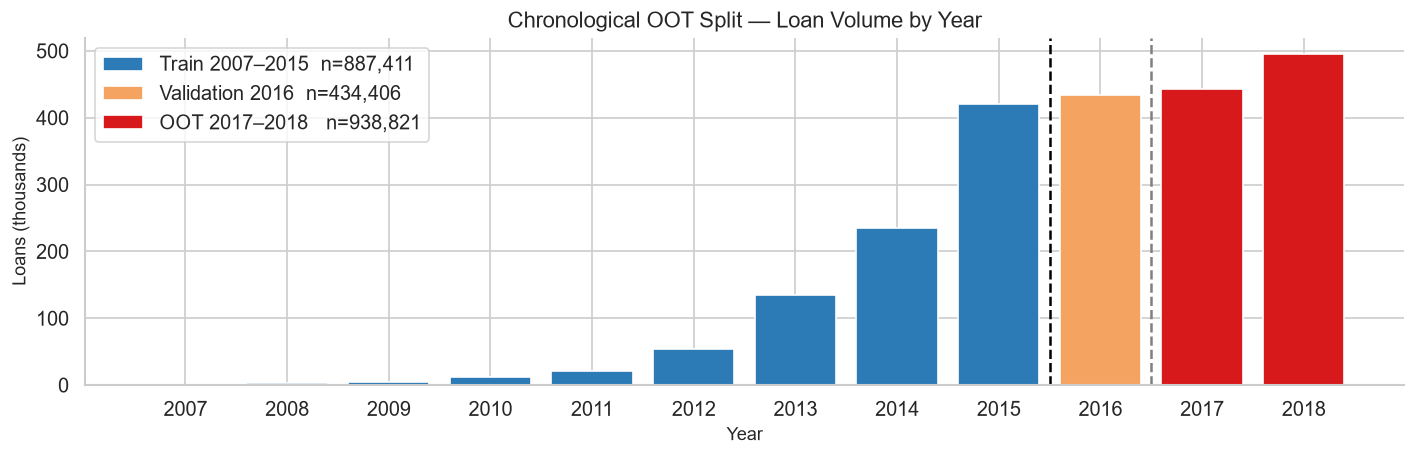

In [ ]:
year_counts = df_master.groupby(df_master['issue_d'].dt.year).size()
split_colors = [
    PLOT_COLOR if y <= 2015 else ('#f4a460' if y == 2016 else ACCENT_COLOR)
    for y in year_counts.index
]

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(year_counts.index, year_counts.values / 1000, color=split_colors, edgecolor='white')
ax.axvline(2015.5, color='black', linestyle='--', linewidth=1.5)
ax.axvline(2016.5, color='grey',  linestyle='--', linewidth=1.5)
ax.legend(handles=[
    Patch(facecolor=PLOT_COLOR,   label=f'Train 2007–2015  n={len(train):,}'),
    Patch(facecolor='#f4a460',    label=f'Validation 2016  n={len(val):,}'),
    Patch(facecolor=ACCENT_COLOR, label=f'OOT 2017–2018   n={len(oot):,}'),
], loc='upper left')
ax.set_xlabel('Year')
ax.set_ylabel('Loans (thousands)')
ax.set_title('Chronological OOT Split — Loan Volume by Year')
ax.set_xticks(year_counts.index)
plt.tight_layout()
save_figure(fig, '03_oot_split.png')
plt.show()

## 5. WoE / IV Analysis — Analytical Reference for LR Feature Selection

**Purpose:** Quantify each feature's discriminatory power for the Logistic Regression scorecard.
Results guide LR feature selection but do **not** remove variables from the master dataset.

WoE is fitted on **training data only** to prevent data leakage.

**Logistic Regression** will use: IV ≥ 0.02 as a starting filter, then refined with VIF and p-values.
**Random Forest / XGBoost / Cox PHM:** Use all 48 master features directly.

In [ ]:
SPECIAL_COLS = ['issue_d', 'default', 'recovery_rate', 'credit_conversion_factor']
WOE_FEATURES = [c for c in MASTER_COLS if c not in SPECIAL_COLS and c in train.columns]

woe_results = {}
iv_summary  = []

def iv_label(iv):
    if iv < 0.02:  return 'Useless'
    if iv < 0.10:  return 'Weak'
    if iv < 0.30:  return 'Medium'
    if iv < 0.50:  return 'Strong'
    return 'Suspicious'

print(f'Computing WoE/IV on training set ({len(train):,} rows)...')
print('NOTE: Low IV does not remove a feature from the master dataset.\n')

for feat in WOE_FEATURES:
    try:
        woe_df, iv, edges = compute_woe_iv(train, feat, target='default', n_bins=10)
        woe_results[feat] = (woe_df, iv, edges)
        label = iv_label(iv)
        iv_summary.append({'feature': feat, 'iv': round(iv, 4), 'iv_label': label})
        woe_df.to_csv(f'{WOE_DIR}/{feat}.csv', index=False)
        print(f'  {feat:<40} IV={iv:.4f}  [{label}]')
    except Exception as e:
        print(f'  {feat:<40} ERROR: {e}')

print(f'\nWoE/IV complete for {len(iv_summary)} features. Tables saved to {WOE_DIR}/')

Computing WoE/IV on training set (887,411 rows)...
NOTE: Low IV does not remove a feature from the master dataset.

  loan_amnt                                IV=0.0181  [Useless]
  term                                     IV=0.1273  [Medium]
  int_rate                                 IV=0.4033  [Strong]
  installment                              IV=0.0158  [Useless]
  grade                                    IV=0.4116  [Strong]
  sub_grade                                IV=0.4431  [Strong]
  emp_length                               IV=0.0023  [Useless]
  annual_inc                               IV=0.0351  [Weak]
  verification_status                      IV=0.0455  [Weak]
  home_ownership                           IV=0.0232  [Weak]
  purpose                                  IV=0.0212  [Weak]
  addr_state                               IV=0.0137  [Useless]
  dti                                      IV=0.0595  [Weak]
  delinq_2yrs                              IV=0.0010  [Useless]
  inq_l

In [ ]:
iv_df = pd.DataFrame(iv_summary).sort_values('iv', ascending=False).reset_index(drop=True)
iv_df.to_csv('artifacts/iv_summary.csv', index=False)

print('=== IV SUMMARY — All 48 Master Features ===')
print('Analytical reference for LR scorecard. Low IV ≠ excluded from master.')
print()
print(iv_df.to_string(index=False))

=== IV SUMMARY — All 48 Master Features ===
Analytical reference for Phase 4 LR. Low IV ≠ excluded from master.

                    feature     iv iv_label
                  sub_grade 0.4431   Strong
                      grade 0.4116   Strong
                   int_rate 0.4033   Strong
                       term 0.1273   Medium
            fico_range_high 0.1162   Medium
             fico_range_low 0.1162   Medium
       acc_open_past_24mths 0.0836     Weak
                        dti 0.0595     Weak
         num_tl_op_past_12m 0.0591     Weak
        verification_status 0.0455     Weak
             mo_sin_rcnt_tl 0.0421     Weak
            tot_hi_cred_lim 0.0411     Weak
      mths_since_recent_inq 0.0368     Weak
                 annual_inc 0.0351     Weak
                tot_cur_bal 0.0348     Weak
           total_rev_hi_lim 0.0303     Weak
       mths_since_recent_bc 0.0302     Weak
                   mort_acc 0.0254     Weak
            num_actv_rev_tl 0.0235     Weak
       

2026-07-26 18:13:10 | INFO     | src.utils | Figure saved → reports\03_iv_all_features.png


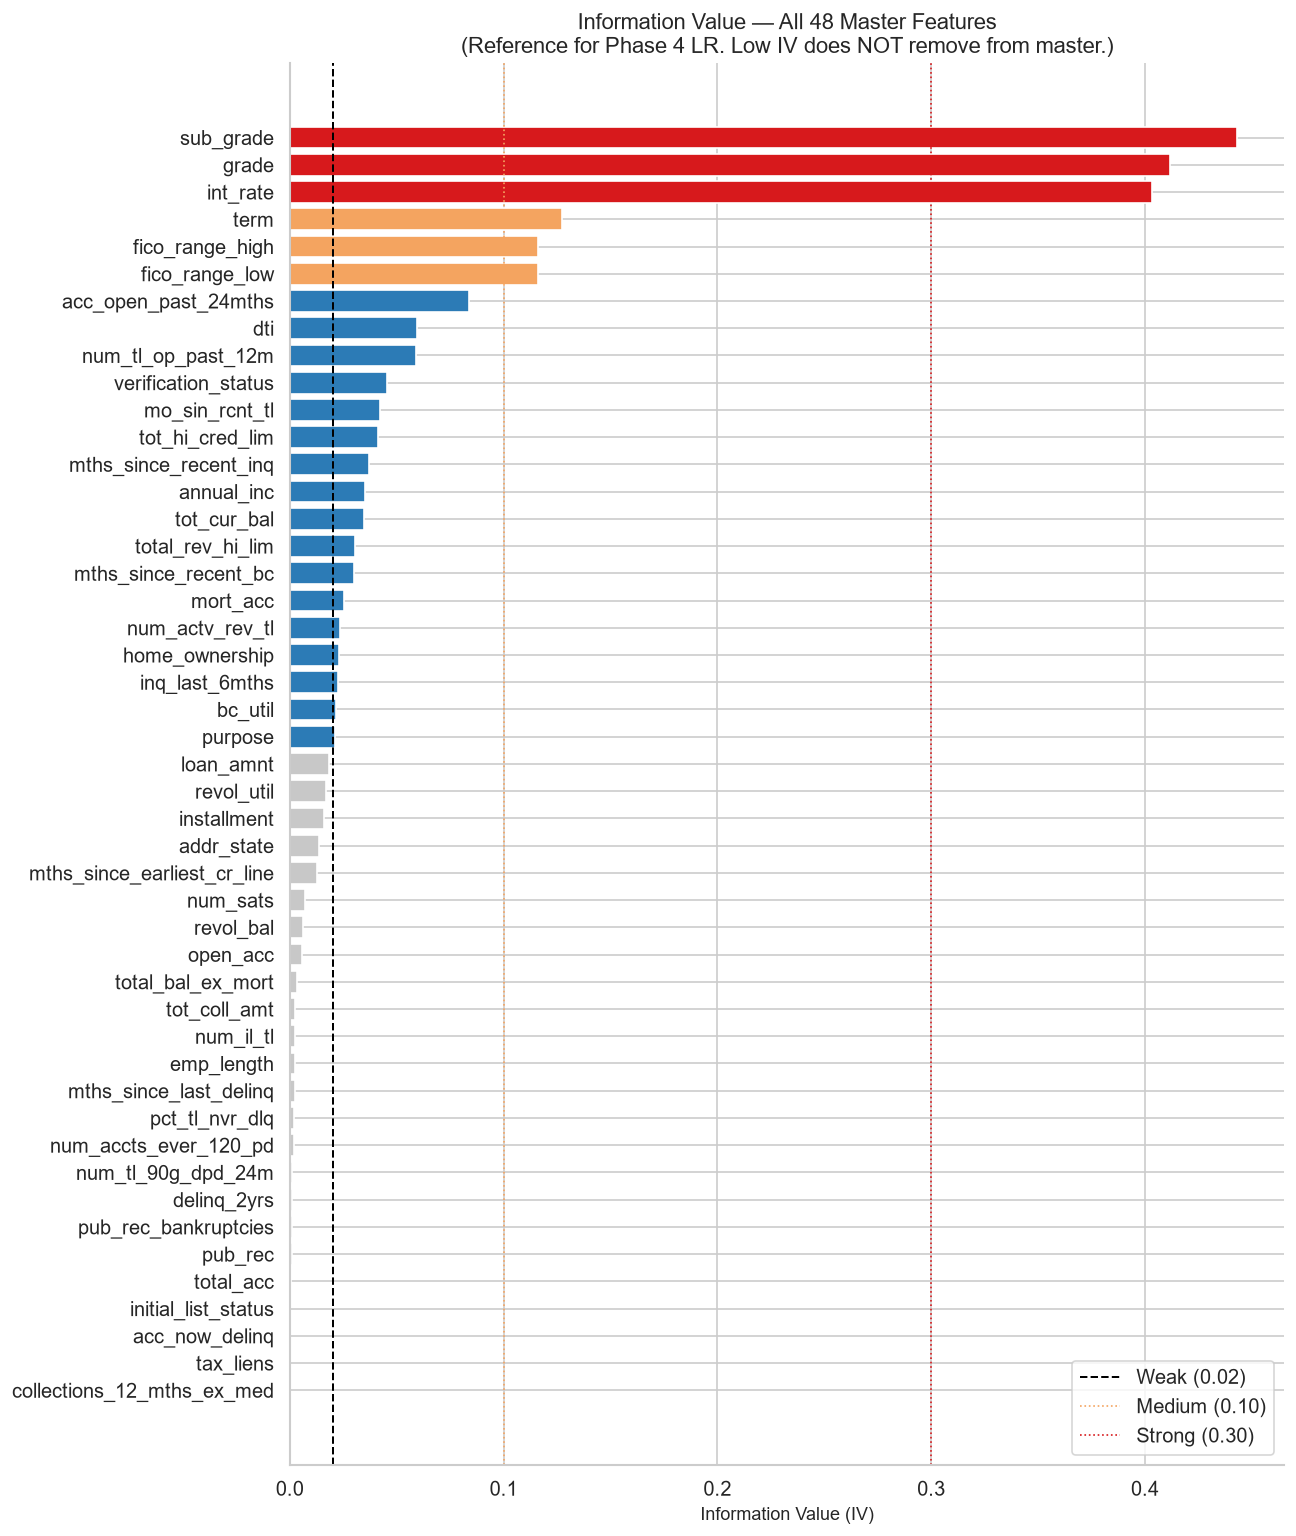

In [ ]:
fig, ax = plt.subplots(figsize=(11, 13))
colors = []
for _, row in iv_df.iterrows():
    if row['iv'] >= 0.30:   colors.append(ACCENT_COLOR)
    elif row['iv'] >= 0.10: colors.append('#f4a460')
    elif row['iv'] >= 0.02: colors.append(PLOT_COLOR)
    else:                    colors.append('#c8c8c8')

ax.barh(iv_df['feature'][::-1], iv_df['iv'][::-1], color=colors[::-1])
ax.axvline(0.02, color='black',      linestyle='--', lw=1.2, label='Weak (0.02)')
ax.axvline(0.10, color='#f4a460',    linestyle=':',  lw=1.0, label='Medium (0.10)')
ax.axvline(0.30, color=ACCENT_COLOR, linestyle=':',  lw=1.0, label='Strong (0.30)')
ax.set_xlabel('Information Value (IV)')
ax.set_title(
    'Information Value — All 48 Master Features\n'
    '(LR scorecard reference. Low IV does NOT remove from master.)'
)
ax.legend(loc='lower right')
plt.tight_layout()
save_figure(fig, '03_iv_all_features.png')
plt.show()

2026-07-26 18:13:20 | INFO     | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-07-26 18:13:20 | INFO     | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-07-26 18:13:22 | INFO     | src.utils | Figure saved → reports\03_woe_top6.png


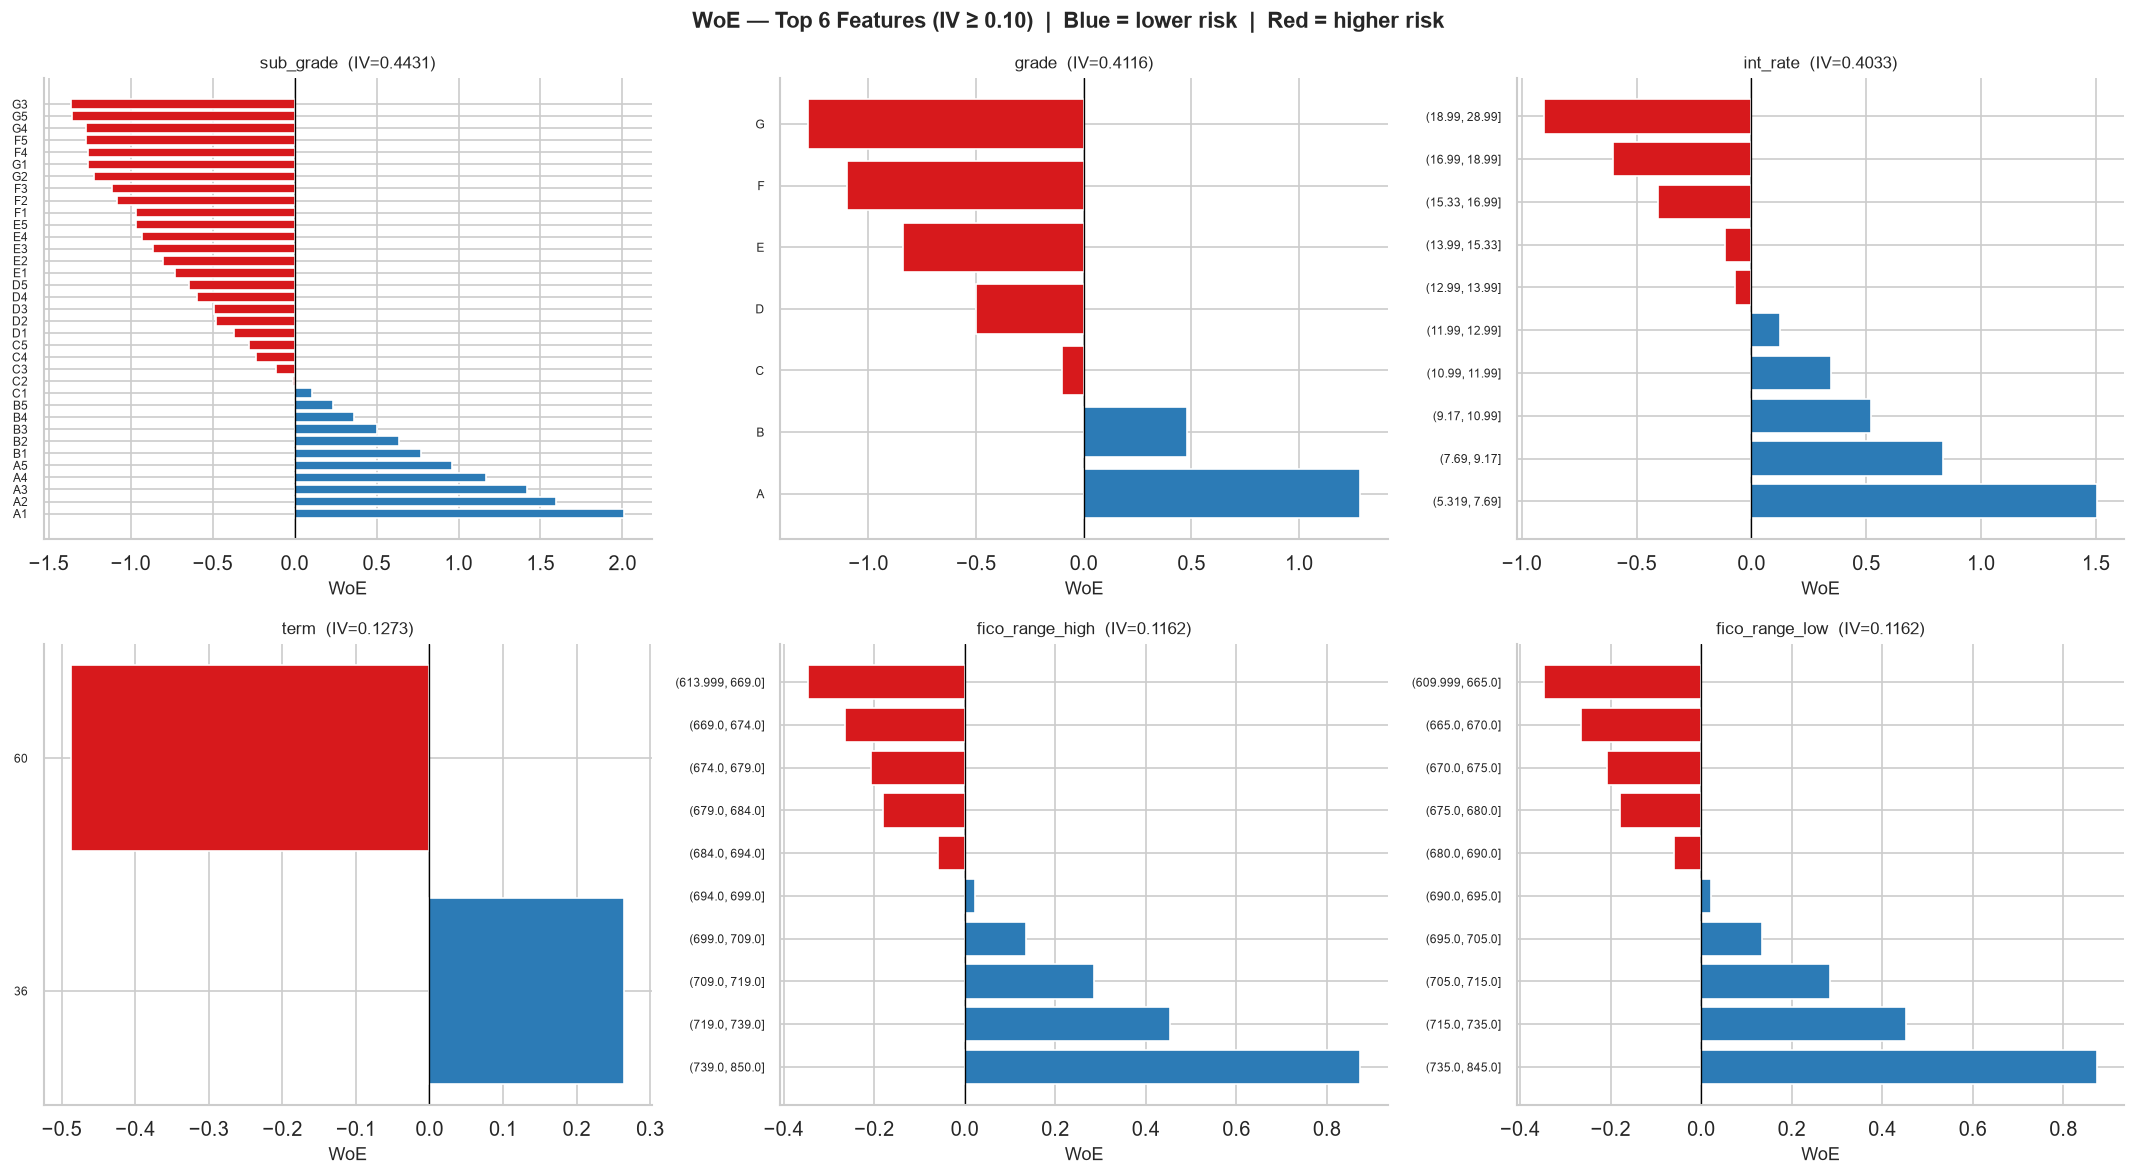

In [ ]:
# WoE plots for top 6 features by IV — validates business logic
top6 = iv_df[iv_df['iv'] >= 0.10].head(6)['feature'].tolist()

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, feat in enumerate(top6):
    woe_df, iv, _ = woe_results[feat]
    bar_colors = [ACCENT_COLOR if w < 0 else PLOT_COLOR for w in woe_df['woe']]
    labels = [str(b)[:22] for b in woe_df['bin']]
    axes[i].barh(labels[::-1], woe_df['woe'][::-1], color=bar_colors[::-1])
    axes[i].axvline(0, color='black', linewidth=0.8)
    axes[i].set_title(f'{feat}  (IV={iv:.4f})', fontsize=10)
    axes[i].set_xlabel('WoE')
    axes[i].tick_params(axis='y', labelsize=7)

fig.suptitle(
    'WoE — Top 6 Features (IV ≥ 0.10)  |  Blue = lower risk  |  Red = higher risk',
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
save_figure(fig, '03_woe_top6.png')
plt.show()

## 6. Save Master Splits

Each parquet contains all 48 master features plus the 4 special columns.
All model notebooks load from here.

In [ ]:
os.makedirs(PROCESSED_DIR, exist_ok=True)

train.to_parquet(f'{PROCESSED_DIR}/train.parquet', index=False)
val.to_parquet(  f'{PROCESSED_DIR}/val.parquet',   index=False)
oot.to_parquet(  f'{PROCESSED_DIR}/oot.parquet',   index=False)

# Save selected_features.json for model notebooks
model_features = [c for c in MASTER_COLS if c not in SPECIAL_COLS]
with open('artifacts/selected_features.json', 'w') as f:
    json.dump({'master_features': model_features, 'special_cols': SPECIAL_COLS,
               'total_features': len(model_features)}, f, indent=2)

print('Master splits saved:')
print(f'  train.parquet  {len(train):>9,} rows x {train.shape[1]} cols')
print(f'  val.parquet    {len(val):>9,} rows x {val.shape[1]} cols')
print(f'  oot.parquet    {len(oot):>9,} rows x {oot.shape[1]} cols')
print(f'\nArtifacts: iv_summary.csv | selected_features.json | woe_tables/ ({len(woe_results)} tables)')

Master splits saved:
  train.parquet    887,411 rows x 51 cols
  val.parquet      434,406 rows x 51 cols
  oot.parquet      938,821 rows x 51 cols

Artifacts: iv_summary.csv | selected_features.json | woe_tables/ (47 tables)


## 7. Summary

| Step | Action | Result |
|------|--------|--------|
| Feature removal | 33 Group B columns removed: 15 HIGH_MISSING + 8 REDUNDANT + 6 MOD_REDUNDANT + 4 NEAR_CONSTANT | All documented with quantitative evidence |
| Master dataset | 29 Group A + 19 Group B retained | 48 model features + 4 special = 52 cols per split |
| Outlier capping | dti ≤ 60, revol_util ≤ 100, annual_inc/revol_bal at 99.9th pct | Applied before splitting |
| OOT split | Train 2007–2015 / Val 2016 / OOT 2017–2018 | Before WoE fitting — no leakage |
| WoE / IV | Computed on training set; 48 WoE tables saved | Analytical reference for LR scorecard development |
| Saved | train / val / oot parquets — same master for all models | Ready for modelling |

### Feature Selection (model-specific)

| Model | Approach | Starting Point |
|-------|----------|---------------|
| **Logistic Regression** | WoE encoding → IV ≥ 0.02 → VIF < 10 → p-value < 0.05 → Scorecard | 48 master features |
| **Random Forest** | All master features → SHAP importance after training | 48 master features |
| **XGBoost** | All master features → gain-based importance after training | 48 master features |
| **Cox PHM** | Survival-specific selection (proportional hazard test) | 48 master features |
| **LGD** | Filter defaulted loans; target = `recovery_rate` | 48 master features |
| **EAD** | Filter defaulted loans; target = `credit_conversion_factor` | 48 master features |

**Next:** `04_pd_modeling.ipynb`